# CS 6220: Data Mining Techniques
## Homework 3

## 0. Dependencies & Environment Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display, Image
from collections import Counter
from sklearn.datasets import make_moons
import torch
import torch.nn as nn
import torch.nn.functional as F

# Ensure reproducible figures
np.random.seed(42)
torch.manual_seed(42)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8


In [2]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\MEGHANA\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


---
# Part 1: K-Nearest Neighbor (k-NN)

### Algorithm Design & Specification
- `knn_predict(X_train, y_train, X_test, y_test, k, distance_func)` implements exact $k$-NN classification.
- General $L_p$ norm:
  $$d_p(\mathbf{u}, \mathbf{v}) = \left(\sum_{i=1}^d |u_i - v_i|^p\right)^{1/p}$$
  where $p=1$ corresponds to Manhattan distance and $p=2$ corresponds to Euclidean distance.
- **Tie-Breaking Rule**: When voting produces a tie among top classes, the algorithm breaks the tie meaningfully by selecting the candidate class with the minimum average distance among its top-$k$ neighbors.


In [3]:
def lp_distance(v1, v2, p=2):
    """Computes the general Lp norm distance between two numerical vectors."""
    v1 = np.asarray(v1, dtype=float)
    v2 = np.asarray(v2, dtype=float)
    return float(np.sum(np.abs(v1 - v2) ** p) ** (1.0 / p))

def euclidean_distance(v1, v2):
    return lp_distance(v1, v2, p=2)

def manhattan_distance(v1, v2):
    return lp_distance(v1, v2, p=1)

def knn_predict(X_train, y_train, X_test, y_test=None, k=3, distance_func=euclidean_distance):
    """
    Performs exact k-NN classification for a single test point X_test.
    Returns:
        Predicted class label (majority vote with distance-weighted tie breaking)
    """
    X_train = np.asarray(X_train, dtype=float)
    y_train = np.asarray(y_train)
    X_test = np.asarray(X_test, dtype=float).ravel()
    
    distances = []
    for i in range(len(X_train)):
        d = distance_func(X_train[i], X_test)
        distances.append((d, y_train[i]))
        
    distances.sort(key=lambda item: item[0])
    k_nearest = distances[:k]
    
    votes = Counter(label for _, label in k_nearest)
    top_counts = votes.most_common()
    
    # Tie breaking: pick class with smallest average distance among top k neighbors
    if len(top_counts) > 1 and top_counts[0][1] == top_counts[1][1]:
        tied_classes = [c for c, count in top_counts if count == top_counts[0][1]]
        class_dist_sum = {c: 0.0 for c in tied_classes}
        for d, c in k_nearest:
            if c in class_dist_sum:
                class_dist_sum[c] += d
        return min(tied_classes, key=lambda c: class_dist_sum[c])
        
    return top_counts[0][0]

def knn_get_votes_and_predict(X_train, y_train, X_test, k=3, distance_func=euclidean_distance):
    """Helper to return vote counts alongside the prediction."""
    X_train = np.asarray(X_train, dtype=float)
    y_train = np.asarray(y_train)
    X_test = np.asarray(X_test, dtype=float).ravel()
    
    distances = []
    for i in range(len(X_train)):
        d = distance_func(X_train[i], X_test)
        distances.append((d, y_train[i]))
    distances.sort(key=lambda item: item[0])
    k_nearest = distances[:k]
    
    votes = {0: sum(1 for _, label in k_nearest if label == 0),
             1: sum(1 for _, label in k_nearest if label == 1)}
    pred = knn_predict(X_train, y_train, X_test, None, k, distance_func)
    return votes, pred


### 2D k-NN Visualization Function & Error Computation

In [4]:
def visualize_knn_boundary(X_train, y_train, k=3, distance_func=euclidean_distance, title=None, ax=None):
    """
    Visualizes 2-D training records and model decision boundary evaluated on a dense 100x100 grid.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
        
    x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
    y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
    
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    
    preds = np.zeros(len(grid_points))
    for idx, pt in enumerate(grid_points):
        preds[idx] = knn_predict(X_train, y_train, pt, None, k, distance_func)
    preds = preds.reshape(xx.shape)
    
    ax.contourf(xx, yy, preds, alpha=0.3, cmap=plt.cm.coolwarm, levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, preds, colors='black', linewidths=1.0, levels=[0.5])
    
    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
               c='#1f77b4', marker='o', edgecolors='k', s=40, label='Class 0')
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
               c='#d62728', marker='^', edgecolors='k', s=45, label='Class 1')
    
    ax.set_title(title or f"k-NN Decision Boundary (k={k})", fontsize=11, fontweight='bold')
    ax.set_xlabel("Feature 1 ($x_1$)")
    ax.set_ylabel("Feature 2 ($x_2$)")
    ax.legend(loc="upper right", framealpha=0.9, fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.5)

def compute_knn_errors(X, y, k=3, distance_func=euclidean_distance):
    """
    Computes training error and Leave-One-Out Cross Validation (LOOCV) test error.
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    n = len(X)
    
    # 1. Training Error
    train_errors = sum(1 for i in range(n) if knn_predict(X, y, X[i], y[i], k, distance_func) != y[i])
    train_error_rate = train_errors / n
    
    # 2. LOOCV Test Error
    loocv_errors = 0
    for i in range(n):
        X_tr = np.delete(X, i, axis=0)
        y_tr = np.delete(y, i, axis=0)
        pred = knn_predict(X_tr, y_tr, X[i], y[i], k, distance_func)
        if pred != y[i]:
            loocv_errors += 1
    test_error_rate = loocv_errors / n
    
    return train_error_rate, test_error_rate


### Question 3: Experimental Predictions on `make_moons` Dataset
We instantiate the dataset using `sklearn.datasets.make_moons(n_samples=200, noise=0.15)` with `np.random.seed(42)`.  
We evaluate test points:
- $P_1 = (0.40, 0.45)$
- $P_2 = (0.08, 0.78)$
- $P_3 = (0.75, -0.15)$  
across distance measures (Euclidean, Manhattan) and neighbor counts $k \in \{1, 3, 5\}$.


In [5]:
np.random.seed(42)
X_moons, y_moons = make_moons(n_samples=200, noise=0.15)
test_points = [(0.40, 0.45), (0.08, 0.78), (0.75, -0.15)]

print(f"{'Point':<16} | {'Metric':<10} | {'k':<2} | {'Class 0 Votes':<13} | {'Class 1 Votes':<13} | {'Predicted Class':<15}")
print("-" * 80)
for pt in test_points:
    for metric_name, dist_fn in [("Euclidean", euclidean_distance), ("Manhattan", manhattan_distance)]:
        for k in [1, 3, 5]:
            votes, pred = knn_get_votes_and_predict(X_moons, y_moons, pt, k, dist_fn)
            pt_str = f"({pt[0]:.2f}, {pt[1]:.2f})"
            print(f"{pt_str:<16} | {metric_name:<10} | {k:<2} | {votes[0]:<13} | {votes[1]:<13} | {pred:<15}")


Point            | Metric     | k  | Class 0 Votes | Class 1 Votes | Predicted Class
--------------------------------------------------------------------------------
(0.40, 0.45)     | Euclidean  | 1  | 1             | 0             | 0              
(0.40, 0.45)     | Euclidean  | 3  | 1             | 2             | 1              
(0.40, 0.45)     | Euclidean  | 5  | 1             | 4             | 1              
(0.40, 0.45)     | Manhattan  | 1  | 1             | 0             | 0              
(0.40, 0.45)     | Manhattan  | 3  | 1             | 2             | 1              
(0.40, 0.45)     | Manhattan  | 5  | 1             | 4             | 1              
(0.08, 0.78)     | Euclidean  | 1  | 0             | 1             | 1              
(0.08, 0.78)     | Euclidean  | 3  | 2             | 1             | 0              
(0.08, 0.78)     | Euclidean  | 5  | 4             | 1             | 0              
(0.08, 0.78)     | Manhattan  | 1  | 0             | 1             | 

#### Question 3d: Minimal Example of Euclidean vs. Manhattan Discrepancy
Below, we demonstrate analytically and visually that two points can receive opposite class assignments under Euclidean vs. Manhattan metric despite identical training data and test query.
- Test Point: $(0, 0)$
- Training Point $A = (0.5, 0.5)$, Class 0
- Training Point $B = (0.0, 0.8)$, Class 1

**Distances:**
- **Euclidean ($L_2$):**
  $$d_E(\text{Test}, A) = \sqrt{0.5^2 + 0.5^2} = \sqrt{0.5} \approx 0.7071$$
  $$d_E(\text{Test}, B) = \sqrt{0^2 + 0.8^2} = 0.8000$$
  Since $d_E(\text{Test}, A) < d_E(\text{Test}, B)$, 1-NN predicts **Class 0**.
- **Manhattan ($L_1$):**
  $$d_M(\text{Test}, A) = |0.5| + |0.5| = 1.0000$$
  $$d_M(\text{Test}, B) = |0| + |0.8| = 0.8000$$
  Since $d_M(\text{Test}, B) < d_M(\text{Test}, A)$, 1-NN predicts **Class 1**.


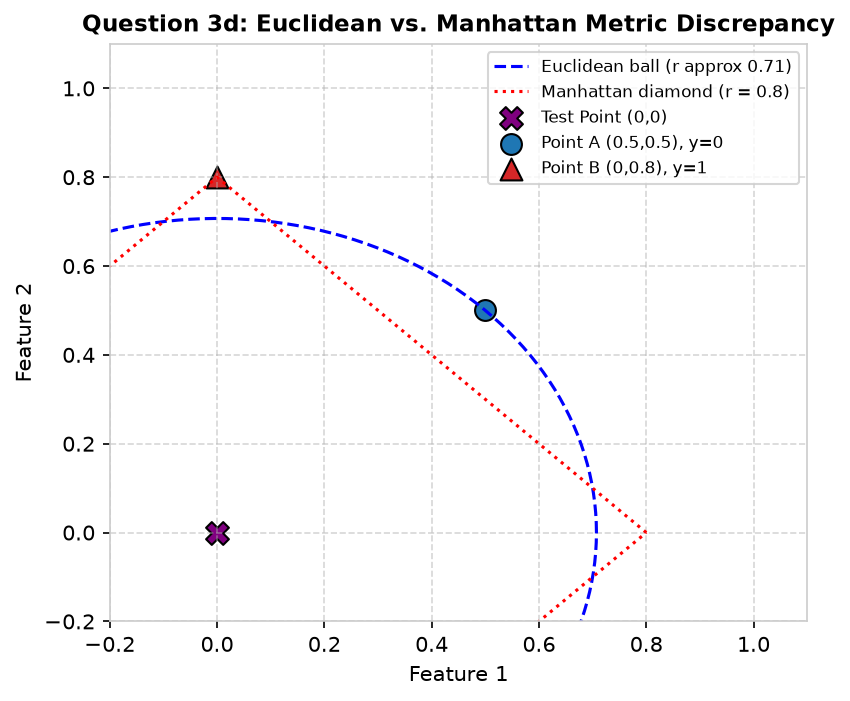

In [6]:
# Visualizing Question 3d Minimal Example
theta = np.linspace(0, 2*np.pi, 200)
fig, ax = plt.subplots(figsize=(6, 5), dpi=150)

ax.plot(0.7071*np.cos(theta), 0.7071*np.sin(theta), 'b--', label='Euclidean ball (r approx 0.71)')
ax.plot([0.8, 0, -0.8, 0, 0.8], [0, 0.8, 0, -0.8, 0], 'r:', label='Manhattan diamond (r = 0.8)')

ax.scatter([0], [0], c='purple', marker='X', s=120, edgecolors='k', label='Test Point (0,0)')
ax.scatter([0.5], [0.5], c='#1f77b4', marker='o', s=100, edgecolors='k', label='Point A (0.5,0.5), y=0')
ax.scatter([0.0], [0.8], c='#d62728', marker='^', s=110, edgecolors='k', label='Point B (0,0.8), y=1')

ax.set_title("Question 3d: Euclidean vs. Manhattan Metric Discrepancy", fontsize=11, fontweight='bold')
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_xlim(-0.2, 1.1)
ax.set_ylim(-0.2, 1.1)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc='upper right', fontsize=8)
plt.show()


### Question 4: 1-NN vs. 10-NN Decision Boundaries & Model Variance

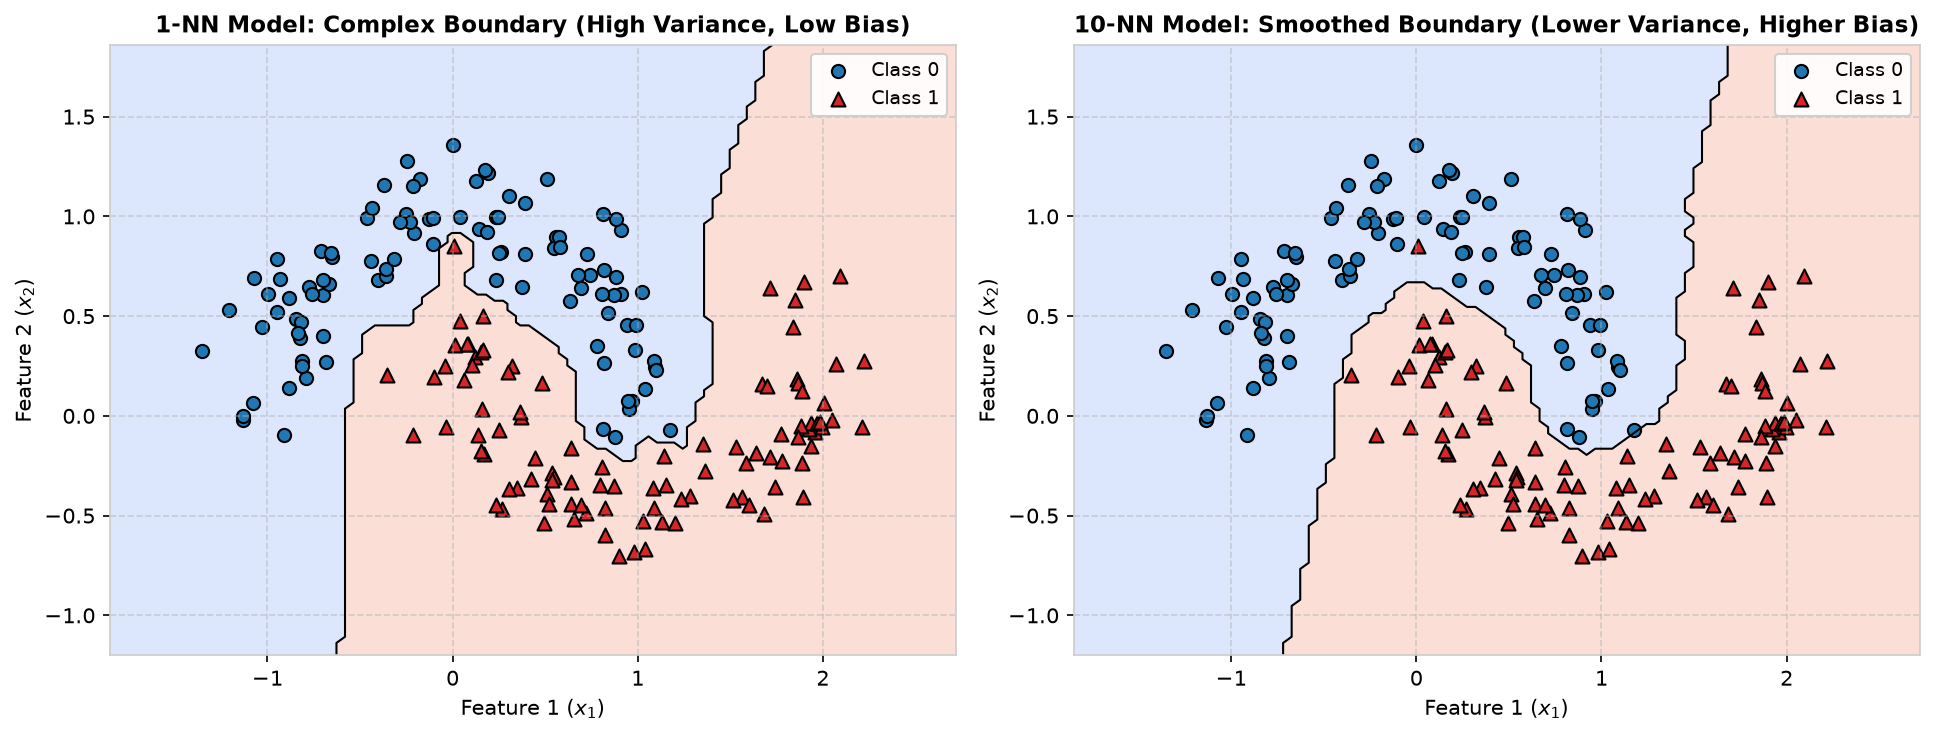

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
visualize_knn_boundary(X_moons, y_moons, k=1, distance_func=euclidean_distance,
                       title="1-NN Model: Complex Boundary (High Variance, Low Bias)", ax=ax1)
visualize_knn_boundary(X_moons, y_moons, k=10, distance_func=euclidean_distance,
                       title="10-NN Model: Smoothed Boundary (Lower Variance, Higher Bias)", ax=ax2)
plt.tight_layout()
plt.show()


### Question 5: k-NN Error Trends from $k=1$ to $k=N$

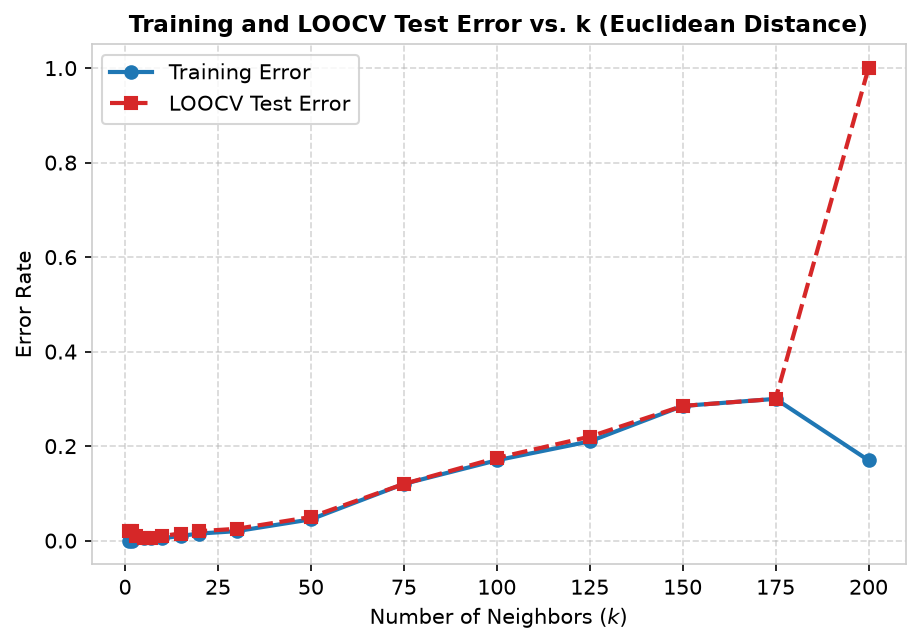

In [8]:
k_vals = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100, 125, 150, 175, 200]
tr_errs, te_errs = [], []

for k in k_vals:
    tr_e, te_e = compute_knn_errors(X_moons, y_moons, k=k, distance_func=euclidean_distance)
    tr_errs.append(tr_e)
    te_errs.append(te_e)

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
ax.plot(k_vals, tr_errs, 'o-', color='#1f77b4', linewidth=2, label='Training Error')
ax.plot(k_vals, te_errs, 's--', color='#d62728', linewidth=2, label='LOOCV Test Error')
ax.set_title("Training and LOOCV Test Error vs. k (Euclidean Distance)", fontsize=11, fontweight='bold')
ax.set_xlabel("Number of Neighbors ($k$)")
ax.set_ylabel("Error Rate")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.show()


---
# Part 2: Neural Networks

### Rosenblatt Perceptron Learning Algorithm
Given training instance $(\mathbf{x}, y)$ with $\mathbf{x} = (x_1, x_2)$ and $y \in \{0, 1\}$:
1. Compute linear activation: $z = w_1 x_1 + w_2 x_2 + b$
2. Heaviside step prediction: $\hat{y} = 1$ if $z \ge 0$ else $0$.
3. Error: $e = y - \hat{y}$
4. Weight and bias updates:
   $$w_1 \leftarrow w_1 + \eta e x_1$$
   $$w_2 \leftarrow w_2 + \eta e x_2$$
   $$b \leftarrow b + \eta e$$


In [9]:
def train_perceptron(training_record, learning_rate, w1, w2, b):
    """
    Implements single-step perceptron training update on record (x1, x2, y).
    """
    x1, x2, y = training_record
    z = w1 * x1 + w2 * x2 + b
    y_hat = 1 if z >= 0.0 else 0
    err = y - y_hat
    
    w1_new = w1 + learning_rate * err * x1
    w2_new = w2 + learning_rate * err * x2
    b_new = b + learning_rate * err
    return w1_new, w2_new, b_new

def perceptron_dataset_error(dataset, w1, w2, b):
    errors = sum(1 for x1, x2, y in dataset if (1 if w1*x1 + w2*x2 + b >= 0.0 else 0) != y)
    return errors / len(dataset)


### Question 7: Perceptron Training on Toy Dataset

Convergence achieved at step 122 with 0 errors!
Optimal parameters: w1=0.200, w2=0.040, b=-0.400


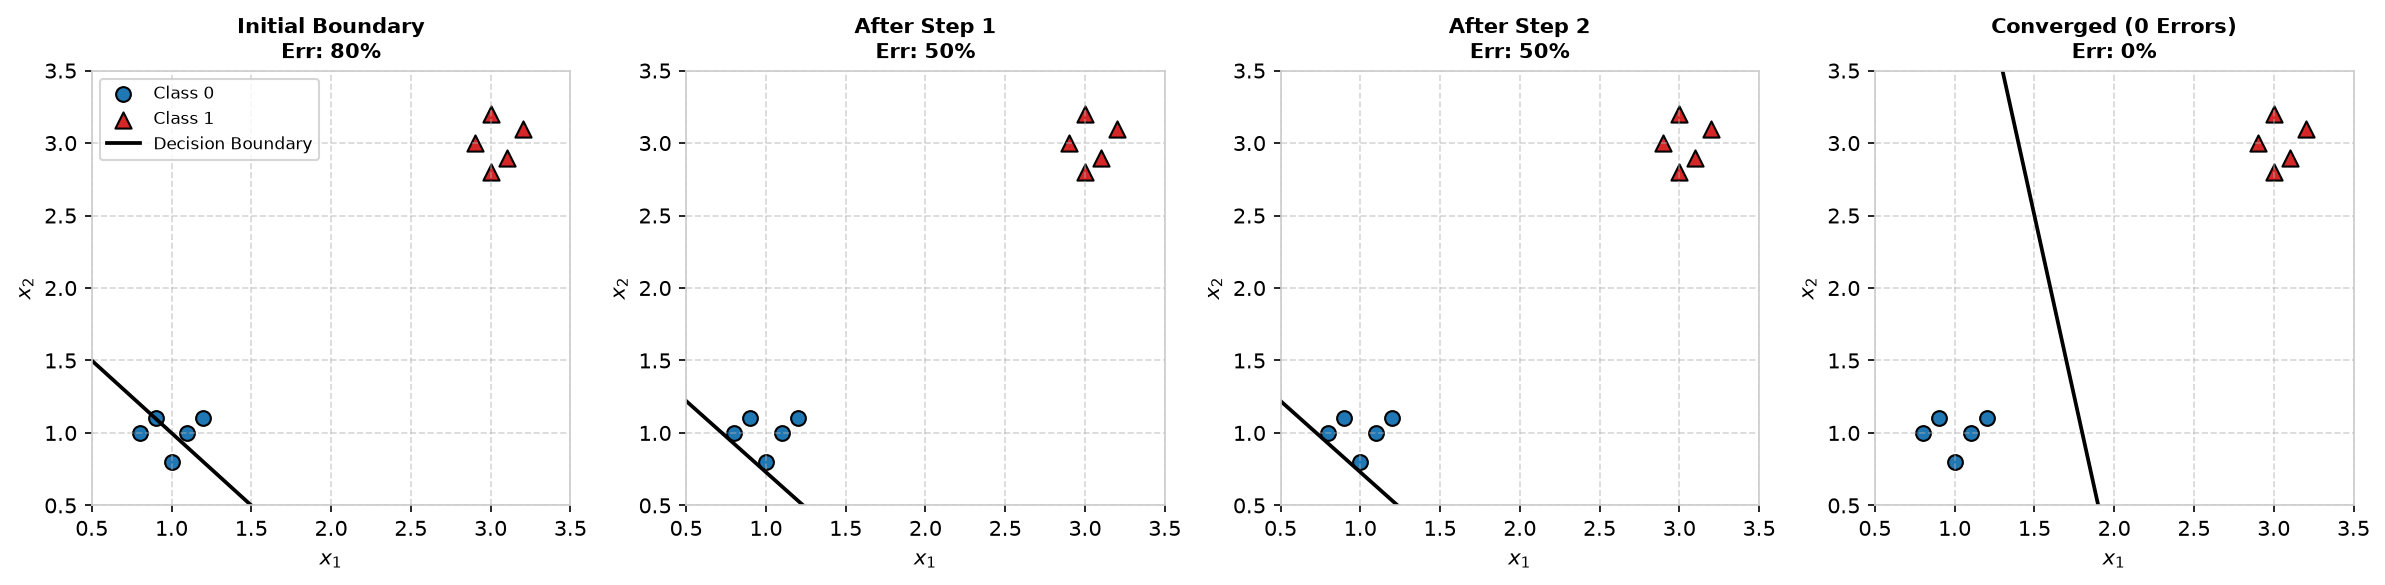

In [10]:
data_q7 = [
    (0.9, 1.1, 0), (1.0, 0.8, 0), (1.1, 1.0, 0), (0.8, 1.0, 0), (1.2, 1.1, 0),
    (3.1, 2.9, 1), (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)
]

w1, w2, b = -1.0, -1.0, 2.0  # Bad initial boundary (80% initial error)
lr = 0.1
weights_hist = [(w1, w2, b)]
err_hist = [perceptron_dataset_error(data_q7, w1, w2, b)]

for step in range(150):
    rec = data_q7[step % len(data_q7)]
    w1, w2, b = train_perceptron(rec, lr, w1, w2, b)
    err = perceptron_dataset_error(data_q7, w1, w2, b)
    weights_hist.append((w1, w2, b))
    err_hist.append(err)
    if err == 0.0:
        print(f"Convergence achieved at step {step + 1} with 0 errors!")
        print(f"Optimal parameters: w1={w1:.3f}, w2={w2:.3f}, b={b:.3f}")
        break

# Plot consecutive steps
data_arr = np.array(data_q7)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=150)
sample_steps = [0, 1, 2, len(weights_hist) - 1]
step_labels = ["Initial Boundary", "After Step 1", "After Step 2", "Converged (0 Errors)"]

x_line = np.linspace(0.5, 3.5, 100)
for ax, s_idx, lbl in zip(axes, sample_steps, step_labels):
    cw1, cw2, cb = weights_hist[s_idx]
    ax.scatter(data_arr[data_arr[:, 2] == 0, 0], data_arr[data_arr[:, 2] == 0, 1],
               c='#1f77b4', marker='o', s=50, edgecolors='k', label='Class 0')
    ax.scatter(data_arr[data_arr[:, 2] == 1, 0], data_arr[data_arr[:, 2] == 1, 1],
               c='#d62728', marker='^', s=60, edgecolors='k', label='Class 1')
    if abs(cw2) > 1e-5:
        y_line = -(cw1 * x_line + cb) / cw2
        ax.plot(x_line, y_line, 'k-', linewidth=1.8, label='Decision Boundary')
    ax.set_xlim(0.5, 3.5)
    ax.set_ylim(0.5, 3.5)
    ax.set_title(f"{lbl}\nErr: {err_hist[s_idx]*100:.0f}%", fontsize=10, fontweight='bold')
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.grid(True, linestyle="--", alpha=0.5)
    if s_idx == 0:
        ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()


### Question 8: Non-Linearly Separable Case (Adding $(1.0, 1.0, 1)$)

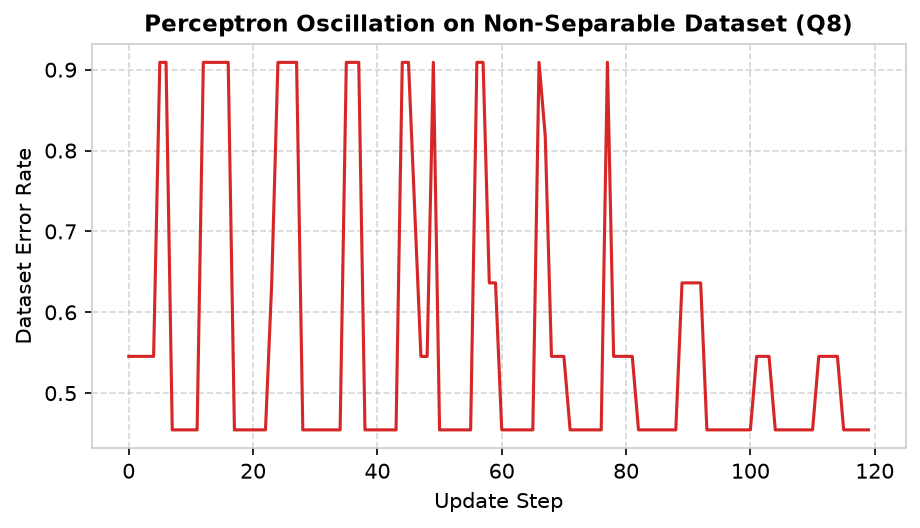

In [11]:
data_q8 = list(data_q7) + [(1.0, 1.0, 1)]
w1, w2, b = -1.0, -1.0, 2.0
q8_err_hist = []

for step in range(300):
    rec = data_q8[step % len(data_q8)]
    w1, w2, b = train_perceptron(rec, 0.1, w1, w2, b)
    err = perceptron_dataset_error(data_q8, w1, w2, b)
    q8_err_hist.append(err)

fig, ax = plt.subplots(figsize=(7, 3.5), dpi=150)
ax.plot(q8_err_hist[:120], color='#d62728', linewidth=1.5)
ax.set_title("Perceptron Oscillation on Non-Separable Dataset (Q8)", fontsize=11, fontweight='bold')
ax.set_xlabel("Update Step")
ax.set_ylabel("Dataset Error Rate")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Question 9: Generalized Single-Unit Artificial Neuron for Regression

#### Mathematical Formulation
For a single record $(x, y)$:
- Pre-activation: $z = w \cdot x + b$
- Output activation: $a = \sigma(z)$
- Chain Rule Gradients:
  $$\frac{\partial C}{\partial a} = \text{cost\_derivative}(y, a)$$
  $$\frac{\partial a}{\partial z} = \text{activation\_derivative}(z, a)$$
  $$\delta = \frac{\partial C}{\partial z} = \frac{\partial C}{\partial a} \cdot \frac{\partial a}{\partial z}$$
  $$\nabla_w C = \delta \cdot x, \quad \nabla_b C = \delta$$
  $$w \leftarrow w - \eta \nabla_w C, \quad b \leftarrow b - \eta \nabla_b C$$


In [12]:
# Activation functions & derivatives
def sigmoid(z): return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
def sigmoid_derivative(z, a=None):
    if a is None: a = sigmoid(z)
    return a * (1.0 - a)

def tanh_func(z): return np.tanh(z)
def tanh_derivative(z, a=None):
    if a is None: a = tanh_func(z)
    return 1.0 - a ** 2

def relu_func(z): return np.maximum(0.0, z)
def relu_derivative(z, a=None): return 1.0 if z > 0.0 else 0.0

def linear_func(z): return z
def linear_derivative(z, a=None): return 1.0

# Cost function derivatives
def cost_derivative_squared_error(y, a): return a - y

def cost_derivative_cross_entropy(y, a):
    eps = 1e-12
    a_clamped = np.clip(a, eps, 1.0 - eps)
    return (a_clamped - y) / (a_clamped * (1.0 - a_clamped))

def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative,
                 activation_func=linear_func):
    x, y = training_record
    z = w * x + b
    a = activation_func(z)
    
    dC_da = cost_derivative(y, a)
    da_dz = activation_derivative(z, a)
    delta = dC_da * da_dz
    
    grad_w = delta * x
    grad_b = delta
    
    w_new = w - learning_rate * grad_w
    b_new = b - learning_rate * grad_b
    return w_new, b_new, grad_w, grad_b


#### Question 9a: Regression Learning Animation on $y = 2x + 3 + \epsilon$

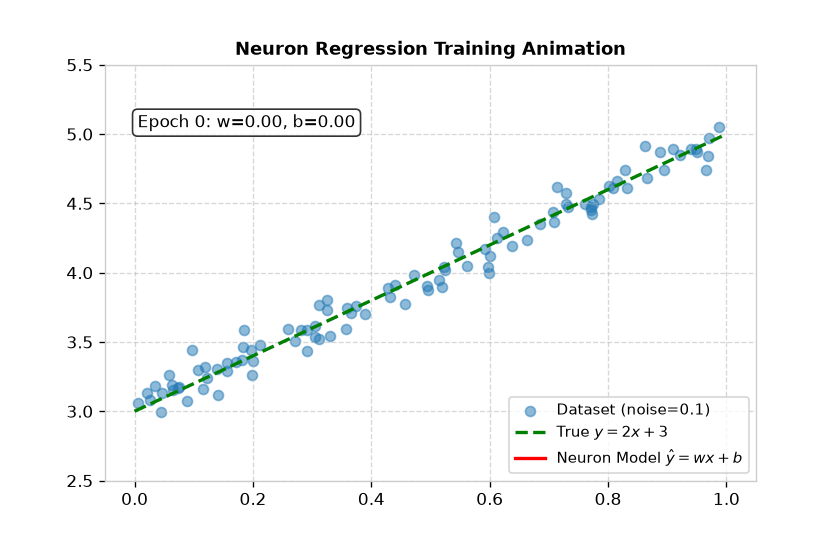

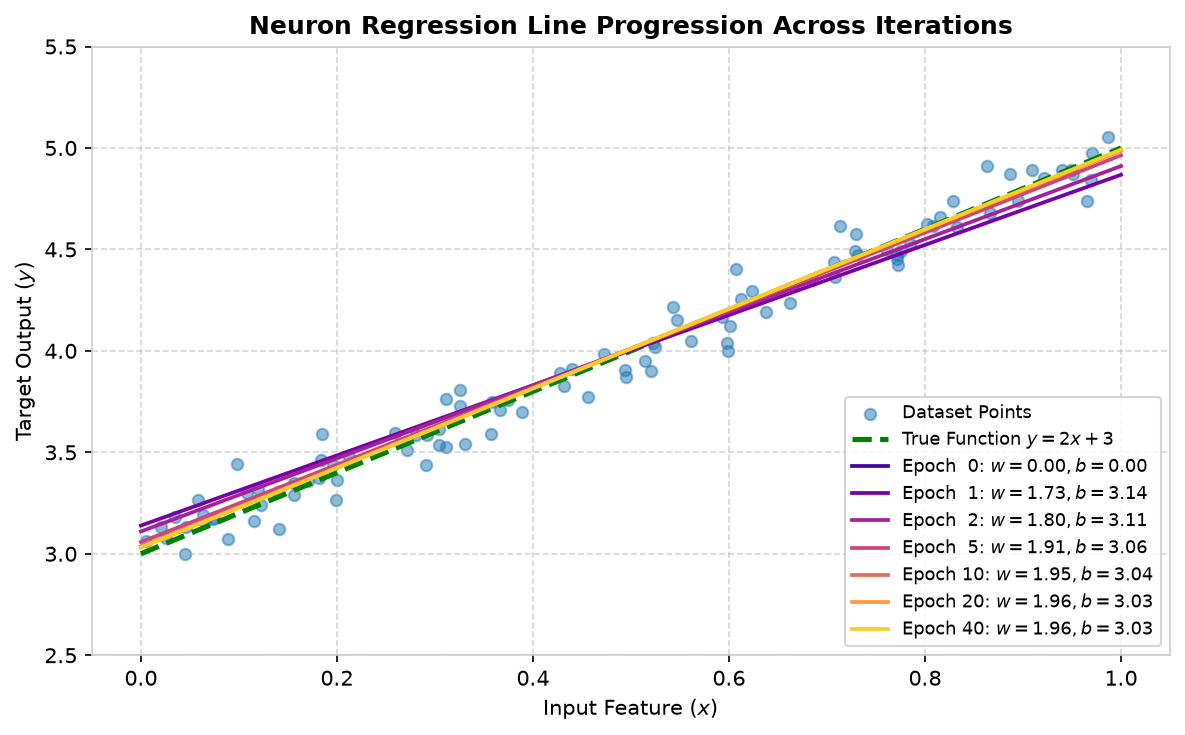

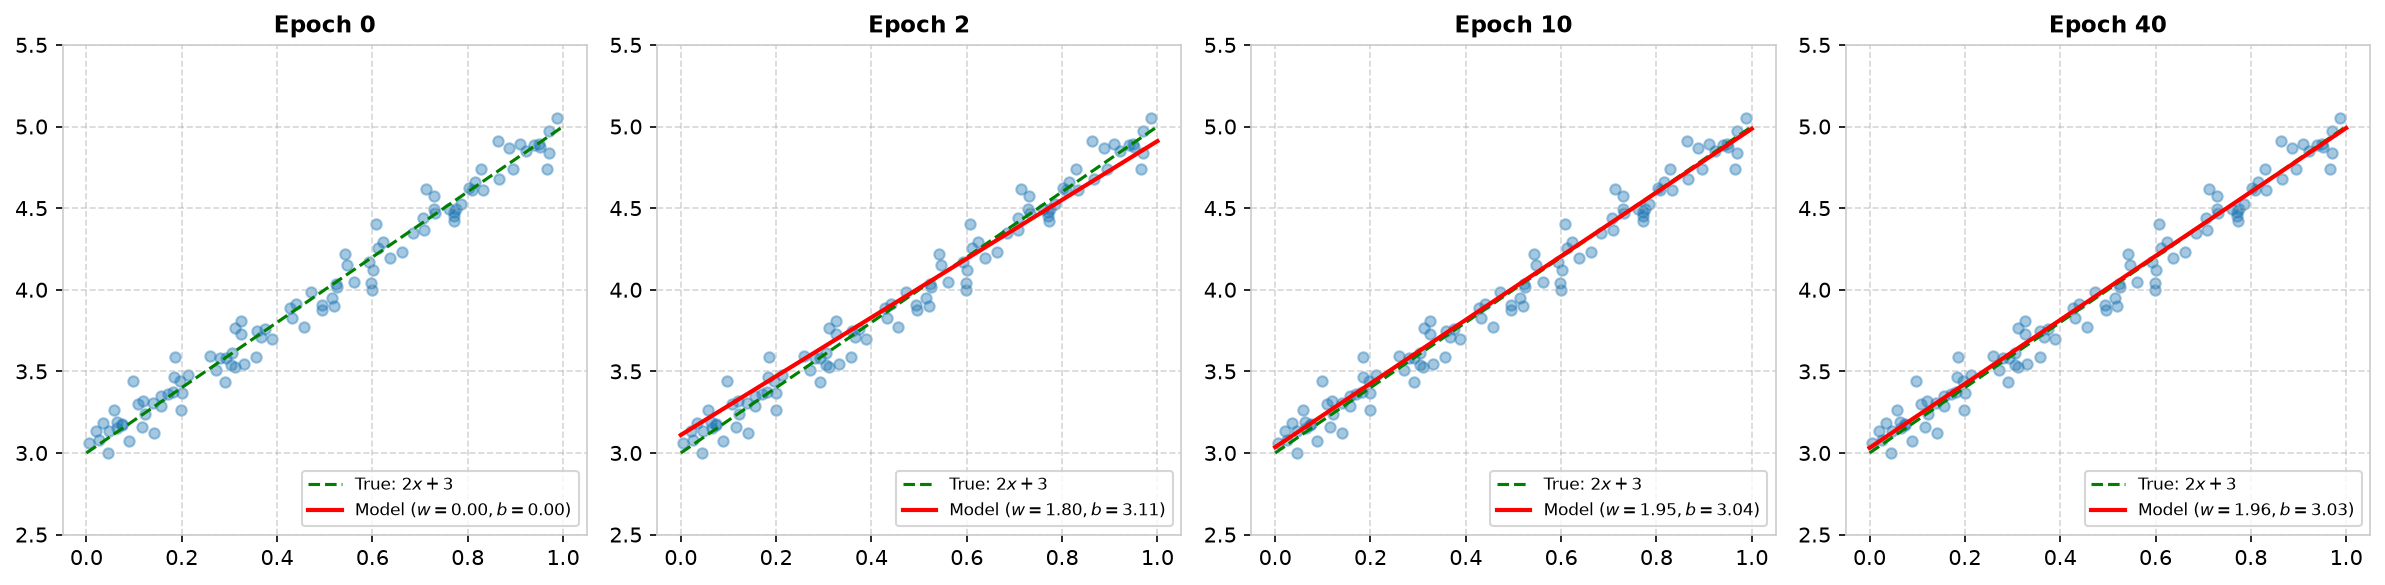

In [13]:
# 9a. Movie-like Animation and Visual Progression of Neuron Learning y = 2x + 3
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display, Image

os.makedirs('figures', exist_ok=True)
np.random.seed(42)
x_data = np.random.uniform(0.0, 1.0, 100)
noise = np.random.normal(0.0, 0.1, 100)
y_data = 2.0 * x_data + 3.0 + noise
records = list(zip(x_data, y_data))

# Train linear neuron
w, b = 0.0, 0.0
lr = 0.05
epochs = 40
history_wb = [(w, b)]
grad_w_epochs, grad_b_epochs = [], []

for ep in range(epochs):
    ep_gw, ep_gb = 0.0, 0.0
    for rec in records:
        w, b, gw, gb = train_neuron(rec, lr, w, b, cost_derivative_squared_error, linear_derivative, linear_func)
        ep_gw += abs(gw)
        ep_gb += abs(gb)
    history_wb.append((w, b))
    grad_w_epochs.append(ep_gw / len(records))
    grad_b_epochs.append(ep_gb / len(records))

# -------------------------------------------------------------
# 1. Movie-like Animation (Rendered as Animated GIF & Interactive Widget)
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
ax.scatter(x_data, y_data, c='#1f77b4', alpha=0.5, label='Dataset (noise=0.1)')
x_grid = np.linspace(0, 1, 100)
ax.plot(x_grid, 2*x_grid + 3, 'g--', linewidth=2, label=r'True $y = 2x + 3$')
line_pred, = ax.plot(x_grid, history_wb[0][0]*x_grid + history_wb[0][1], 'r-', linewidth=2, label=r'Neuron Model $\hat{y} = wx + b$')
txt = ax.text(0.05, 0.85, f"Epoch 0: w={history_wb[0][0]:.2f}, b={history_wb[0][1]:.2f}",
              transform=ax.transAxes, fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(2.5, 5.5)
ax.set_title("Neuron Regression Training Animation", fontsize=11, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

def animate(frame):
    cw, cb = history_wb[frame]
    line_pred.set_data(x_grid, cw*x_grid + cb)
    txt.set_text(f"Epoch {frame}: w={cw:.2f}, b={cb:.2f}")
    return line_pred, txt

ani = animation.FuncAnimation(fig, animate, frames=len(history_wb), interval=100, blit=False)

# Save as animated GIF so it renders natively and reliably in any viewer (including VS Code)
gif_path = 'figures/q9_regression_animation.gif'
ani.save(gif_path, writer=animation.PillowWriter(fps=5))
plt.close(fig)

# Display animated GIF in notebook
display(Image(filename=gif_path))

# Also provide interactive scrub/play/pause controls if supported by Jupyter environment
try:
    display(HTML(ani.to_jshtml()))
except Exception:
    pass

# -------------------------------------------------------------
# 2. Plotted Progression Images (Always visible in all notebook viewers)
# -------------------------------------------------------------
fig_prog, ax_prog = plt.subplots(figsize=(8, 5), dpi=150)
ax_prog.scatter(x_data, y_data, c='#1f77b4', alpha=0.5, s=30, label='Dataset Points')
ax_prog.plot(x_grid, 2*x_grid + 3, 'g--', linewidth=2.5, label=r'True Function $y = 2x + 3$')

sample_epochs = [0, 1, 2, 5, 10, 20, len(history_wb) - 1]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(sample_epochs)))

for ep, col in zip(sample_epochs, colors):
    cw, cb = history_wb[ep]
    ax_prog.plot(x_grid, cw*x_grid + cb, color=col, linewidth=1.8,
                 label=f"Epoch {ep:2d}: $w={cw:.2f}, b={cb:.2f}$")

ax_prog.set_title("Neuron Regression Line Progression Across Iterations", fontsize=12, fontweight='bold')
ax_prog.set_xlabel("Input Feature ($x$)")
ax_prog.set_ylabel("Target Output ($y$)")
ax_prog.set_xlim(-0.05, 1.05)
ax_prog.set_ylim(2.5, 5.5)
ax_prog.grid(True, linestyle="--", alpha=0.5)
ax_prog.legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 3. Side-by-Side Snapshots of Key Epochs
# -------------------------------------------------------------
fig_snap, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=150)
snapshot_epochs = [0, 2, 10, len(history_wb) - 1]

for ax_s, ep in zip(axes, snapshot_epochs):
    cw, cb = history_wb[ep]
    ax_s.scatter(x_data, y_data, c='#1f77b4', alpha=0.4, s=25)
    ax_s.plot(x_grid, 2*x_grid + 3, 'g--', linewidth=1.5, label='True: $2x+3$')
    ax_s.plot(x_grid, cw*x_grid + cb, 'r-', linewidth=2, label=f'Model ($w={cw:.2f}, b={cb:.2f}$)')
    ax_s.set_title(f"Epoch {ep}", fontsize=11, fontweight='bold')
    ax_s.set_xlim(-0.05, 1.05)
    ax_s.set_ylim(2.5, 5.5)
    ax_s.grid(True, linestyle="--", alpha=0.5)
    ax_s.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()


#### Question 9c & 9d: Learning Rates & Gradient Magnitudes Across Epochs

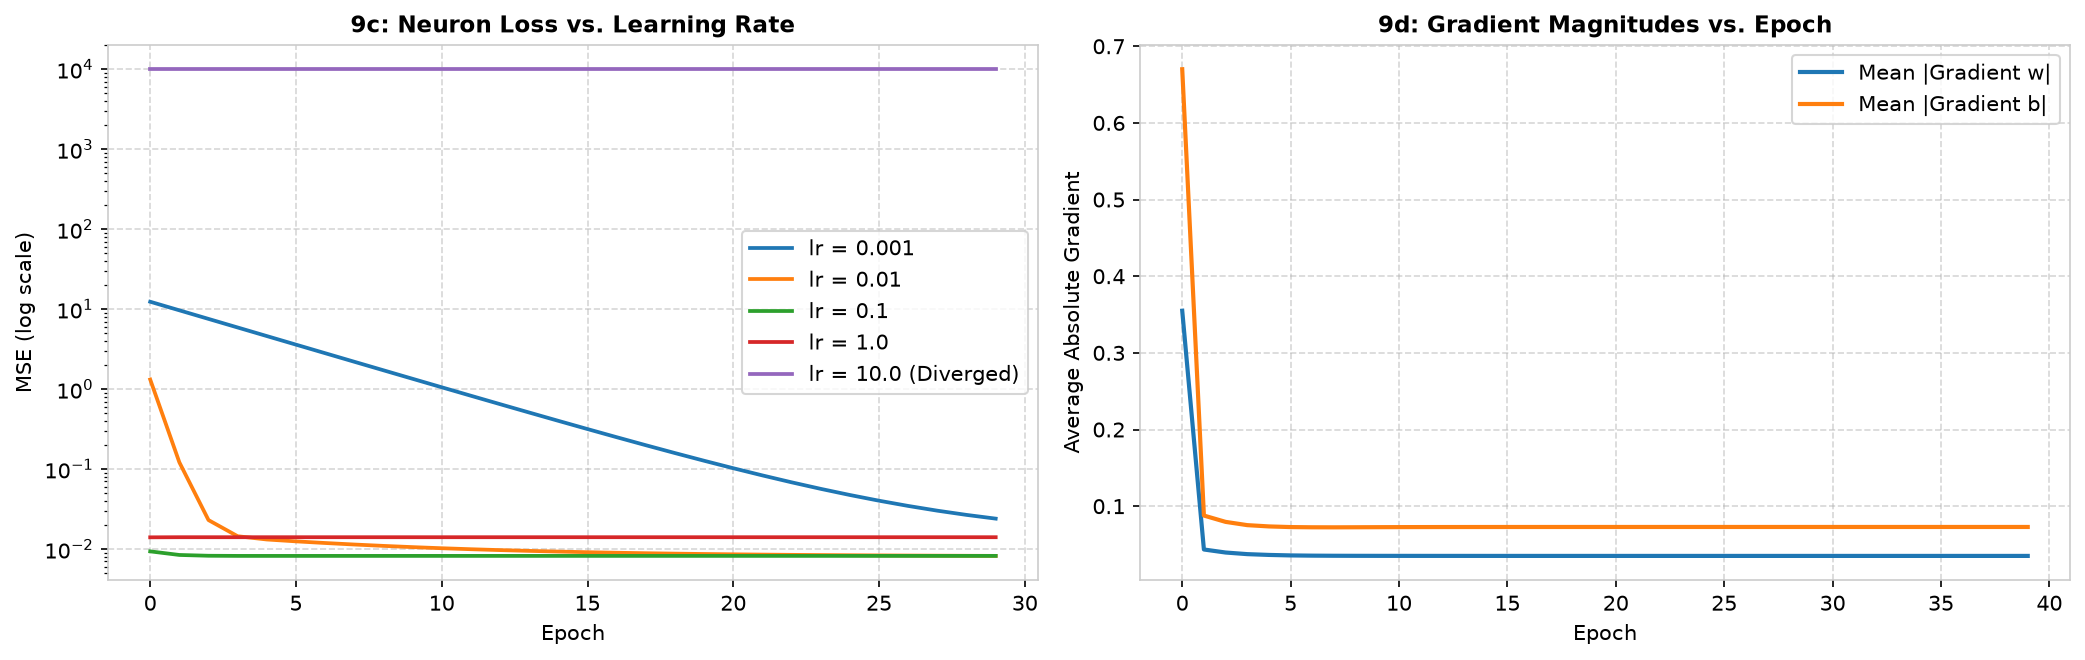

In [14]:
# 9c: Learning Rate Sweeps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=150)
lrs = [0.001, 0.01, 0.1, 1.0, 10.0]

for test_lr in lrs:
    cw, cb = 0.0, 0.0
    mses = []
    diverged = False
    for ep in range(30):
        for rec in records:
            cw, cb, _, _ = train_neuron(rec, test_lr, cw, cb, cost_derivative_squared_error, linear_derivative, linear_func)
            if np.isnan(cw) or abs(cw) > 1e4:
                diverged = True
                break
        if diverged:
            mses.extend([1e4] * (30 - len(mses)))
            break
        mses.append(np.mean((cw * x_data + cb - y_data) ** 2))
    ax1.plot(mses, label=f"lr = {test_lr} {'(Diverged)' if diverged else ''}", linewidth=1.8)

ax1.set_yscale('log')
ax1.set_title("9c: Neuron Loss vs. Learning Rate", fontsize=11, fontweight='bold')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MSE (log scale)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# 9d: Gradient Evolution
ax2.plot(grad_w_epochs, label='Mean |Gradient w|', color='#1f77b4', linewidth=2)
ax2.plot(grad_b_epochs, label='Mean |Gradient b|', color='#ff7f0e', linewidth=2)
ax2.set_title("9d: Gradient Magnitudes vs. Epoch", fontsize=11, fontweight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Average Absolute Gradient")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


---
# Part 3: Multi-Layer Perceptron & Gradient Flow Analysis (Questions 10–12)

### Architecture & Experimental Configuration from Demo Notebook
- **Network Depth:** 4 hidden layers of 32 units each + 1 output layer of 10 units = **5 layers total**
- **Activations:** All 5 layers use **Sigmoid** activation
- **Cost Function:** **Mean Squared Error (MSE)**


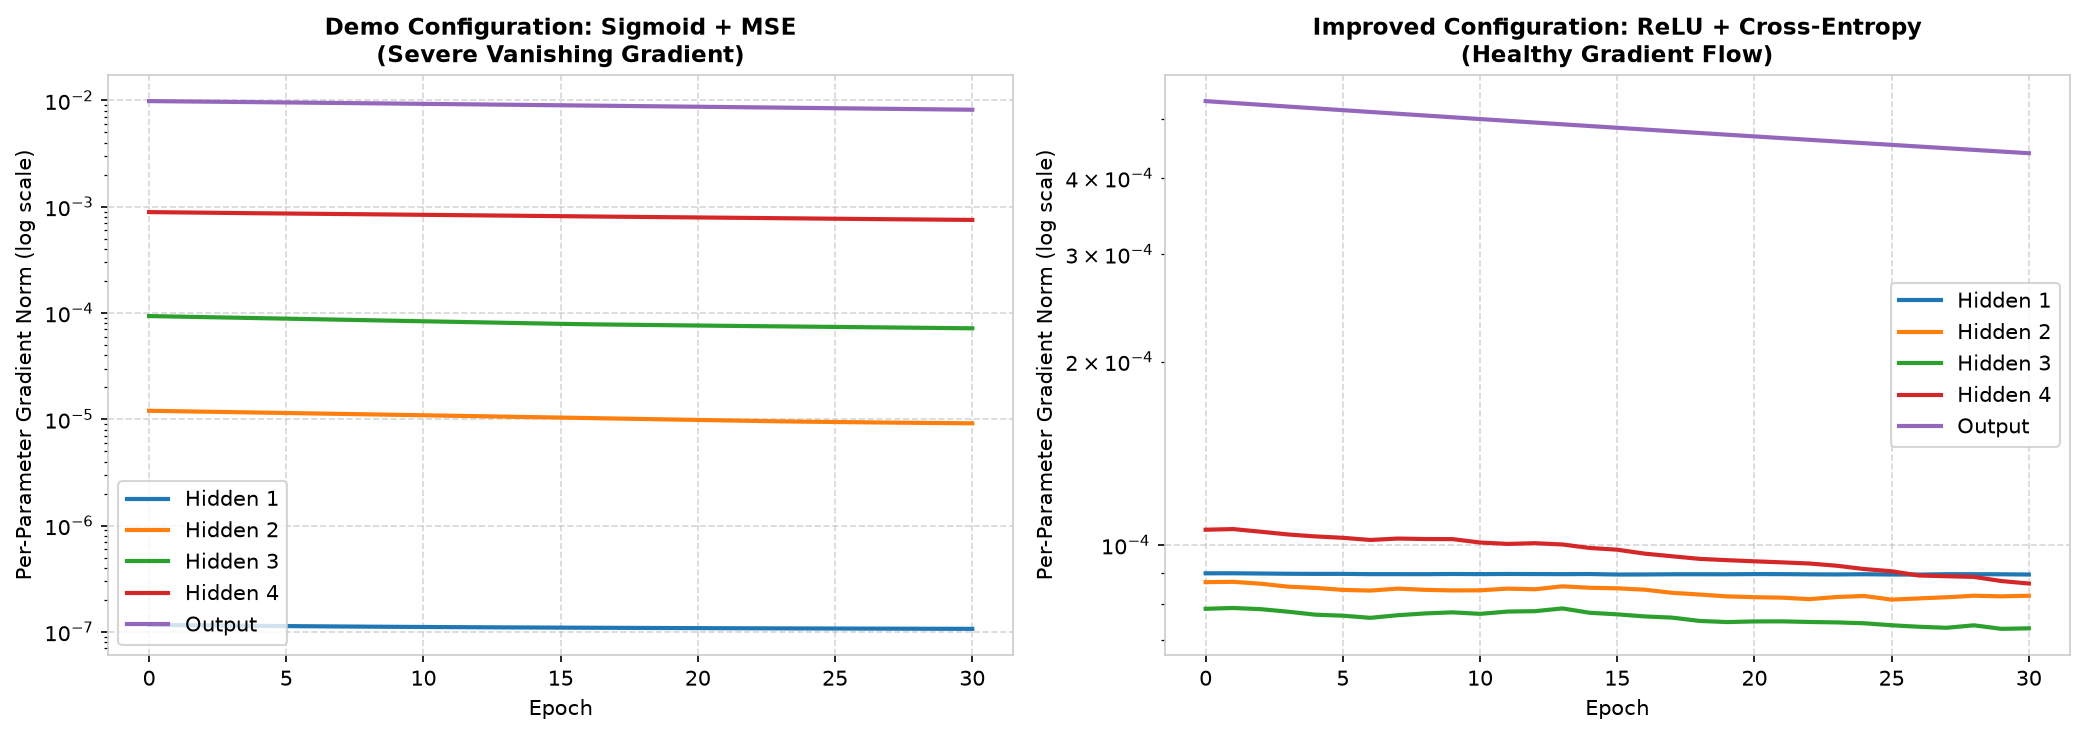

In [15]:
# Multi-Layer Perceptron (MNIST) Gradient Flow Exploration (Pure PyTorch)

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_units, activations, output_dim):
        super().__init__()
        sizes = [input_dim] + list(hidden_units) + [output_dim]
        self.layers = nn.ModuleList([nn.Linear(sizes[i], sizes[i + 1]) for i in range(len(sizes) - 1)])
        self.act_names = activations
        
    def forward(self, x):
        for layer, act_name in zip(self.layers, self.act_names):
            if act_name == 'sigmoid':
                x = torch.sigmoid(layer(x))
            elif act_name == 'relu':
                x = F.relu(layer(x))
            elif act_name == 'identity':
                x = layer(x)
        return x

def evaluate_gradient_flow(hidden_units, activations, cost_type, epochs=30, lr=0.05):
    torch.manual_seed(42)
    X = torch.randn(1000, 784)
    y = torch.randint(0, 10, (1000,))
    model = MLP(784, hidden_units, activations, 10)
    
    grad_history = []
    for ep in range(epochs + 1):
        model.eval()
        model.zero_grad()
        out = model(X)
        loss = F.mse_loss(out, F.one_hot(y, 10).float()) if cost_type == 'mse' else F.cross_entropy(out, y)
        loss.backward()
        
        norms = [layer.weight.grad.abs().mean().item() for layer in model.layers]
        grad_history.append(norms)
        
        if ep < epochs:
            model.train()
            # Standard PyTorch SGD parameter update
            with torch.no_grad():
                for p in model.parameters():
                    if p.grad is not None:
                        p.data -= lr * p.grad.data
    return np.array(grad_history)

# Experiment 1: Demo Notebook Configuration (4 hidden layers of 32 units, all Sigmoid, MSE)
grads_sig_mse = evaluate_gradient_flow([32, 32, 32, 32], ['sigmoid'] * 5, 'mse')

# Experiment 2: Modern Configuration (4 hidden layers of 32 units, ReLU hidden, Identity output, Cross-Entropy)
grads_relu_ce = evaluate_gradient_flow([32, 32, 32, 32], ['relu'] * 4 + ['identity'], 'cross_entropy')

# Plotting the Per-Layer Gradient Flow Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
labels = [f"Hidden {i+1}" for i in range(4)] + ["Output"]

for i in range(5):
    ax1.plot(grads_sig_mse[:, i], label=labels[i], linewidth=2)
ax1.set_yscale('log')
ax1.set_title("Demo Configuration: Sigmoid + MSE\n(Severe Vanishing Gradient)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Per-Parameter Gradient Norm (log scale)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

for i in range(5):
    ax2.plot(grads_relu_ce[:, i], label=labels[i], linewidth=2)
ax2.set_yscale('log')
ax2.set_title("Improved Configuration: ReLU + Cross-Entropy\n(Healthy Gradient Flow)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Per-Parameter Gradient Norm (log scale)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()
